# Prophet – Notebook Revisi Seminar Hasil

**Revisi utama:** pembagian data menjadi **80% training dan 20% testing**.

Evaluasi tetap menggunakan **MAE, RMSE, dan MAPE**.

Setelah evaluasi, model final dilatih dengan seluruh data historis dan melakukan forecast **14 hari**.

In [1]:
# ============================================================
# HASIL PENELITIAN PROPHET - VERSI REVISI
# ============================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from prophet import Prophet

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

warnings.filterwarnings("ignore")

plt.style.use("ggplot")

# ============================================================
# LOKASI FILE
# ============================================================

BASE_DIR = os.getcwd()

FILE_EXCEL = os.path.join(
    BASE_DIR, "dataset/data_clean_ok.xlsx"
)

OUTPUT_FOLDER = os.path.join(
    BASE_DIR, "hasil_penelitian"
)

os.makedirs(
    OUTPUT_FOLDER,
    exist_ok=True
)

# ============================================================
# PILIH PRODUK
# ============================================================

SHEET = "surya_kaleng"

CHANGEPOINT = {
    "surya_kaleng": 0.1,
    "sampoerna_16": 0.05,
    "aqua_600ml": 0.05,
    "aqua_1500ml": 0.01,
    "indomie": 0.01,
    "golda": 0.1,
    "teh_botol_450ml": 0.01,
    "surya_16": 0.1
}

CURRENT_SCALE = CHANGEPOINT[SHEET]

LEAD_TIME = 14

print("=" * 60)
print("HASIL PENELITIAN PROPHET - VERSI REVISI")
print("=" * 60)
print("Dataset :", FILE_EXCEL)
print("Produk  :", SHEET)
print("Train   : 80%")
print("Test    : 20%")
print("Lead Time :", LEAD_TIME, "hari")
print("=" * 60)

Importing plotly failed. Interactive plots will not work.


HASIL PENELITIAN PROPHET - VERSI REVISI
Dataset : d:\SKRIPSI\POS\PROPHET\dataset/data_clean_ok.xlsx
Produk  : surya_kaleng
Train   : 80%
Test    : 20%
Lead Time : 14 hari


In [2]:
# ============================================================
# MEMBACA DATASET
# ============================================================

df = pd.read_excel(
    FILE_EXCEL,
    sheet_name=SHEET
)

df["ds"] = pd.to_datetime(df["ds"])

df = df.sort_values("ds").reset_index(drop=True)

print("Data awal:")
print(df.head())

print("\nInformasi data:")
print(df.info())

print("\nStatistik data:")
print(df.describe())

Data awal:
          ds    y
0 2023-01-01   56
1 2023-01-02   95
2 2023-01-03   67
3 2023-01-04   76
4 2023-01-05  100

Informasi data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1092 entries, 0 to 1091
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   ds      1092 non-null   datetime64[ns]
 1   y       1092 non-null   int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 17.2 KB
None

Statistik data:
                                  ds            y
count                           1092  1092.000000
mean   2024-07-02 00:39:33.626373632   116.458791
min              2023-01-01 00:00:00     0.000000
25%              2023-09-30 18:00:00    91.000000
50%              2024-07-03 12:00:00   112.000000
75%              2025-04-02 06:00:00   143.250000
max              2025-12-31 00:00:00   284.000000
std                              NaN    42.775297


In [3]:
# ============================================================
# 4. PREPROCESSING DATA
# ============================================================

# Pastikan format kolom sesuai dengan kebutuhan Prophet
df["ds"] = pd.to_datetime(
    df["ds"],
    errors="coerce"
)

df["y"] = pd.to_numeric(
    df["y"],
    errors="coerce"
)

# Hapus baris yang tanggal atau nilai penjualannya tidak valid
df_model = df.dropna(
    subset=["ds", "y"]
).copy()

# Urutkan berdasarkan waktu
df_model = (
    df_model
    .sort_values("ds")
    .reset_index(drop=True)
)

print("=" * 60)
print("PREPROCESSING DATA")
print("=" * 60)

print("Jumlah data :", len(df_model))
print(
    "Periode     :",
    df_model["ds"].min(),
    "s/d",
    df_model["ds"].max()
)

print("\nJumlah nilai 0 pada penjualan:",
      (df_model["y"] == 0).sum())

print("\nMissing value:")
print(df_model[["ds", "y"]].isna().sum())

display(df_model.head())

PREPROCESSING DATA
Jumlah data : 1092
Periode     : 2023-01-01 00:00:00 s/d 2025-12-31 00:00:00

Jumlah nilai 0 pada penjualan: 5

Missing value:
ds    0
y     0
dtype: int64


,ds,y
0,2023-01-01,56
1,2023-01-02,95
2,2023-01-03,67
3,2023-01-04,76
4,2023-01-05,100


## 5. Pembagian Data 80:20

Karena data adalah time series, pembagian dilakukan berdasarkan urutan waktu dan **tanpa shuffle**.

- 80% data awal → training
- 20% data terakhir → testing

In [4]:
# ============================================================
# 5. PEMBAGIAN DATA TRAINING DAN TESTING
# 80% TRAINING - 20% TESTING
# ============================================================

TRAIN_RATIO = 0.80
TEST_RATIO = 0.20

train_size = int(len(df_model) * TRAIN_RATIO)

train = df_model.iloc[:train_size].copy()
test = df_model.iloc[train_size:].copy()

print("=" * 60)
print("PEMBAGIAN DATA 80:20")
print("=" * 60)

print(f"Total data : {len(df_model)}")

print(
    f"Training   : {len(train)} data "
    f"({len(train) / len(df_model) * 100:.2f}%)"
)

print(
    f"Testing    : {len(test)} data "
    f"({len(test) / len(df_model) * 100:.2f}%)"
)

print("\nPeriode Training:")
print(
    train["ds"].min(),
    "s/d",
    train["ds"].max()
)

print("\nPeriode Testing:")
print(
    test["ds"].min(),
    "s/d",
    test["ds"].max()
)

PEMBAGIAN DATA 80:20
Total data : 1092
Training   : 873 data (79.95%)
Testing    : 219 data (20.05%)

Periode Training:
2023-01-01 00:00:00 s/d 2025-05-26 00:00:00

Periode Testing:
2025-05-27 00:00:00 s/d 2025-12-31 00:00:00


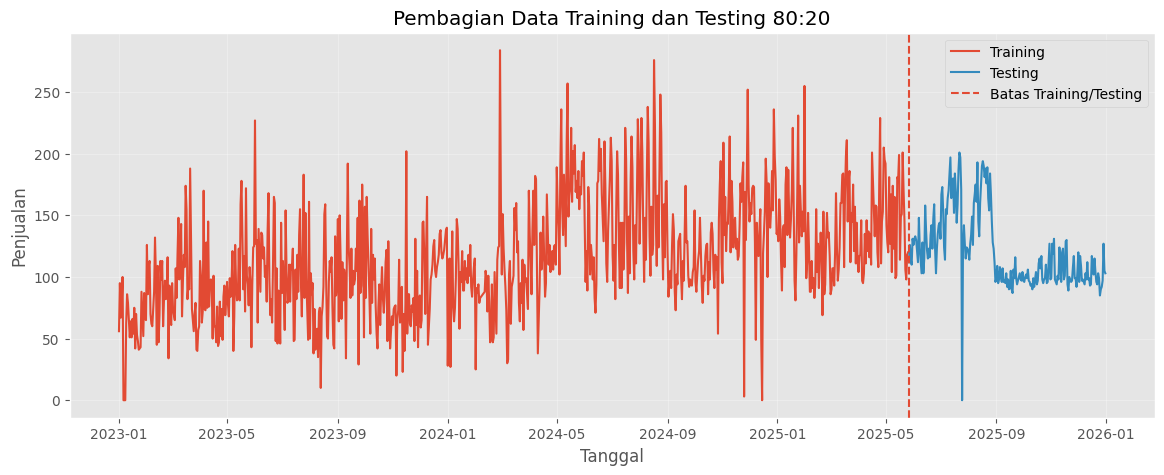

In [5]:
# 6. VISUALISASI SPLIT
plt.figure(figsize=(14, 5))
plt.plot(train["ds"], train["y"], label="Training")
plt.plot(test["ds"], test["y"], label="Testing")
plt.axvline(test["ds"].iloc[0], linestyle="--", label="Batas Training/Testing")
plt.title("Pembagian Data Training dan Testing 80:20")
plt.xlabel("Tanggal")
plt.ylabel("Penjualan")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 7. Model Prophet untuk Evaluasi

Ini adalah **baseline revisi**. Konfigurasi Prophet yang sekarang digunakan dipertahankan terlebih dahulu supaya kita dapat melihat dampak perubahan pembagian data secara jelas.

In [6]:
# 7. MODEL EVALUASI
model_eval = Prophet(
    changepoint_prior_scale=CURRENT_SCALE,
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)

model_eval.fit(train)
print("Model evaluasi berhasil dilatih.")

01:50:04 - cmdstanpy - INFO - Chain [1] start processing
01:50:04 - cmdstanpy - INFO - Chain [1] done processing


Model evaluasi berhasil dilatih.


In [7]:
# 8. PREDIKSI DATA TESTING
future_test = test[["ds"]].copy()
forecast_test = model_eval.predict(future_test)

y_true = test["y"].to_numpy()
y_pred = forecast_test["yhat"].to_numpy()

print("Jumlah aktual   :", len(y_true))
print("Jumlah prediksi :", len(y_pred))

Jumlah aktual   : 219
Jumlah prediksi : 219


In [8]:
# 9. EVALUASI MAE, RMSE, MAPE
mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))

# MAPE dihitung pada aktual != 0 agar tidak terjadi pembagian dengan nol.
mask = y_true != 0
mape = (
    mean_absolute_percentage_error(y_true[mask], y_pred[mask]) * 100
    if mask.sum() > 0 else np.nan
)

print("===== HASIL EVALUASI 80:20 =====")
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAPE : {mape:.2f}%")

===== HASIL EVALUASI 80:20 =====
MAE  : 25.72
RMSE : 30.17
MAPE : 21.98%


In [9]:
# ============================================================
# EKSPERIMEN CHANGEPOINT PRIOR SCALE
# ============================================================

scales = [
    0.001,
    0.01,
    0.05,
    0.1
]

hasil_cps = []

for scale in scales:

    model = Prophet(
        changepoint_prior_scale=scale,
        yearly_seasonality=True,
        weekly_seasonality=True,
        daily_seasonality=False
    )

    model.fit(train)

    forecast = model.predict(
        test[["ds"]]
    )

    y_true = test["y"].values
    y_pred = forecast["yhat"].values

    mae_test = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse_test = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    mask = y_true != 0

    mape_test = (
        mean_absolute_percentage_error(
            y_true[mask],
            y_pred[mask]
        ) * 100
    )

    hasil_cps.append({
        "changepoint_prior_scale": scale,
        "MAE": mae_test,
        "RMSE": rmse_test,
        "MAPE": mape_test
    })

hasil_cps = pd.DataFrame(hasil_cps)

hasil_cps = hasil_cps.sort_values(
    "MAE"
).reset_index(drop=True)

display(hasil_cps)

01:50:04 - cmdstanpy - INFO - Chain [1] start processing
01:50:05 - cmdstanpy - INFO - Chain [1] done processing
01:50:05 - cmdstanpy - INFO - Chain [1] start processing
01:50:05 - cmdstanpy - INFO - Chain [1] done processing
01:50:05 - cmdstanpy - INFO - Chain [1] start processing
01:50:05 - cmdstanpy - INFO - Chain [1] done processing
01:50:06 - cmdstanpy - INFO - Chain [1] start processing
01:50:06 - cmdstanpy - INFO - Chain [1] done processing


,changepoint_prior_scale,MAE,RMSE,MAPE
0,0.100,25.716841,30.172479,21.981985
1,0.050,34.980184,39.480361,31.643468
2,0.010,46.448930,51.824046,42.961759
3,0.001,50.717675,56.307961,47.014701


In [10]:
# 10. TABEL AKTUAL VS PREDIKSI
hasil_testing = test[["ds", "y"]].copy()
hasil_testing["yhat"] = y_pred
hasil_testing["error"] = hasil_testing["y"] - hasil_testing["yhat"]
hasil_testing["absolute_error"] = hasil_testing["error"].abs()

display(hasil_testing)

,ds,y,yhat,error,absolute_error
873,2025-05-27,112,161.006098,-49.006098,49.006098
874,2025-05-28,126,164.691422,-38.691422,38.691422
875,2025-05-29,114,162.256037,-48.256037,48.256037
876,2025-05-30,110,166.936861,-56.936861,56.936861
877,2025-05-31,131,160.019530,-29.019530,29.019530
...,...,...,...,...,...
1087,2025-12-27,92,136.430925,-44.430925,44.430925
1088,2025-12-28,97,128.720756,-31.720756,31.720756
1089,2025-12-29,127,130.408986,-3.408986,3.408986
1090,2025-12-30,105,130.434080,-25.434080,25.434080


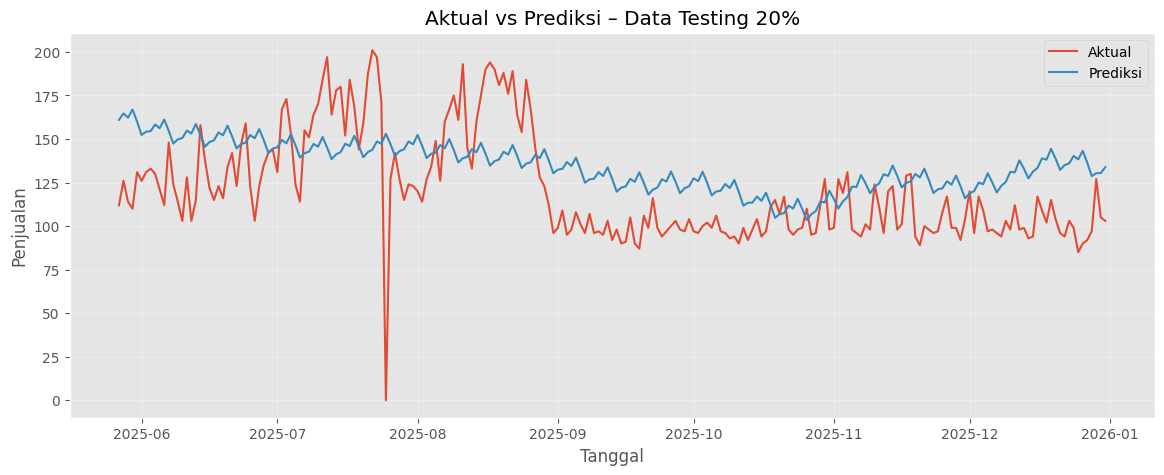

In [11]:
# 11. GRAFIK AKTUAL VS PREDIKSI
plt.figure(figsize=(14, 5))
plt.plot(hasil_testing["ds"], hasil_testing["y"], label="Aktual")
plt.plot(hasil_testing["ds"], hasil_testing["yhat"], label="Prediksi")
plt.title("Aktual vs Prediksi – Data Testing 20%")
plt.xlabel("Tanggal")
plt.ylabel("Penjualan")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 12. Komponen Prophet

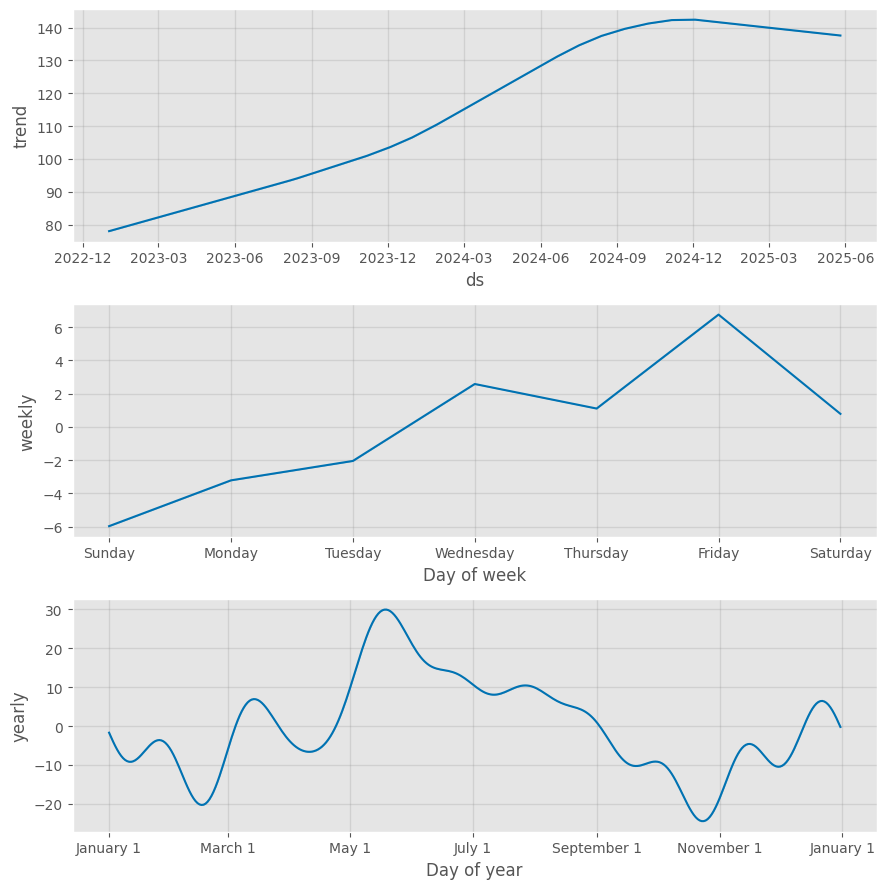

In [12]:
# 12. KOMPONEN MODEL
future_component = model_eval.make_future_dataframe(periods=0)
forecast_component = model_eval.predict(future_component)
model_eval.plot_components(forecast_component)
plt.show()

In [13]:
seasonality_modes = [
    "additive",
    "multiplicative"
]

hasil_mode = []

# Gunakan kandidat CPS terbaik dari eksperimen sebelumnya
BEST_CPS = hasil_cps.iloc[0]["changepoint_prior_scale"]

for mode in seasonality_modes:

    print(
        f"Menguji seasonality_mode = {mode}"
    )

    model = Prophet(
        changepoint_prior_scale=BEST_CPS,
        yearly_seasonality=True,
        weekly_seasonality=True,
        daily_seasonality=False,
        seasonality_mode=mode
    )

    model.fit(train)

    forecast = model.predict(
        test[["ds"]]
    )

    y_true_mode = test["y"].values
    y_pred_mode = forecast["yhat"].values

    # MAE
    mae_mode = mean_absolute_error(
        y_true_mode,
        y_pred_mode
    )

    # RMSE
    rmse_mode = np.sqrt(
        mean_squared_error(
            y_true_mode,
            y_pred_mode
        )
    )

    # MAPE
    mask_mode = y_true_mode != 0

    if mask_mode.sum() > 0:
        mape_mode = (
            mean_absolute_percentage_error(
                y_true_mode[mask_mode],
                y_pred_mode[mask_mode]
            ) * 100
        )
    else:
        mape_mode = np.nan

    hasil_mode.append({
        "seasonality_mode": mode,
        "changepoint_prior_scale": BEST_CPS,
        "MAE": mae_mode,
        "RMSE": rmse_mode,
        "MAPE": mape_mode
    })


hasil_mode = pd.DataFrame(hasil_mode)

print(
    "\n===== HASIL EKSPERIMEN SEASONALITY MODE ====="
)

display(
    hasil_mode.round(2)
)


01:50:07 - cmdstanpy - INFO - Chain [1] start processing


Menguji seasonality_mode = additive


01:50:07 - cmdstanpy - INFO - Chain [1] done processing
01:50:07 - cmdstanpy - INFO - Chain [1] start processing


Menguji seasonality_mode = multiplicative


01:50:08 - cmdstanpy - INFO - Chain [1] done processing



===== HASIL EKSPERIMEN SEASONALITY MODE =====


,seasonality_mode,changepoint_prior_scale,MAE,RMSE,MAPE
0,additive,0.1,25.72,30.17,21.98
1,multiplicative,0.1,19.70,25.77,15.37


In [14]:
# ============================================================
# 12.3 EKSPERIMEN HOLIDAY INDONESIA
# ============================================================

hasil_holiday = []

BEST_CPS = 0.1
BEST_MODE = "multiplicative"


# ============================================================
# MODEL 1 - TANPA HOLIDAY
# ============================================================

print("Menguji model TANPA holiday...")

model_no_holiday = Prophet(
    changepoint_prior_scale=BEST_CPS,
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode=BEST_MODE
)

model_no_holiday.fit(train)

forecast_no_holiday = model_no_holiday.predict(
    test[["ds"]]
)

y_true_holiday = test["y"].values
y_pred_no_holiday = forecast_no_holiday["yhat"].values

mae_no_holiday = mean_absolute_error(
    y_true_holiday,
    y_pred_no_holiday
)

rmse_no_holiday = np.sqrt(
    mean_squared_error(
        y_true_holiday,
        y_pred_no_holiday
    )
)

mask_holiday = y_true_holiday != 0

mape_no_holiday = (
    mean_absolute_percentage_error(
        y_true_holiday[mask_holiday],
        y_pred_no_holiday[mask_holiday]
    ) * 100
)


hasil_holiday.append({
    "Holiday": "Tidak digunakan",
    "MAE": mae_no_holiday,
    "RMSE": rmse_no_holiday,
    "MAPE": mape_no_holiday
})


# ============================================================
# MODEL 2 - DENGAN HOLIDAY INDONESIA
# ============================================================

print("Menguji model DENGAN holiday Indonesia...")

model_holiday = Prophet(
    changepoint_prior_scale=BEST_CPS,
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode=BEST_MODE
)

model_holiday.add_country_holidays(
    country_name="Indonesia"
)

model_holiday.fit(train)

forecast_holiday = model_holiday.predict(
    test[["ds"]]
)

y_pred_holiday = forecast_holiday["yhat"].values

mae_holiday = mean_absolute_error(
    y_true_holiday,
    y_pred_holiday
)

rmse_holiday = np.sqrt(
    mean_squared_error(
        y_true_holiday,
        y_pred_holiday
    )
)

mape_holiday = (
    mean_absolute_percentage_error(
        y_true_holiday[mask_holiday],
        y_pred_holiday[mask_holiday]
    ) * 100
)


hasil_holiday.append({
    "Holiday": "Indonesia",
    "MAE": mae_holiday,
    "RMSE": rmse_holiday,
    "MAPE": mape_holiday
})


# ============================================================
# HASIL
# ============================================================

hasil_holiday = pd.DataFrame(
    hasil_holiday
)

print("\n===== HASIL EKSPERIMEN HOLIDAY =====")

display(
    hasil_holiday.round(2)
)

01:50:08 - cmdstanpy - INFO - Chain [1] start processing


Menguji model TANPA holiday...


01:50:08 - cmdstanpy - INFO - Chain [1] done processing


Menguji model DENGAN holiday Indonesia...


01:50:09 - cmdstanpy - INFO - Chain [1] start processing
01:50:09 - cmdstanpy - INFO - Chain [1] done processing



===== HASIL EKSPERIMEN HOLIDAY =====


,Holiday,MAE,RMSE,MAPE
0,Tidak digunakan,19.70,25.77,15.37
1,Indonesia,19.77,27.25,14.97


In [15]:
# ============================================================
# 12.4 EKSPERIMEN KOMPONEN SEASONALITY
# ============================================================

seasonality_configs = [
    {
        "nama": "Yearly + Weekly",
        "yearly": True,
        "weekly": True
    },
    {
        "nama": "Yearly saja",
        "yearly": True,
        "weekly": False
    },
    {
        "nama": "Weekly saja",
        "yearly": False,
        "weekly": True
    }
]

hasil_seasonality = []

BEST_CPS = 0.1
BEST_MODE = "multiplicative"

for config in seasonality_configs:

    print(f"Menguji: {config['nama']}")

    model = Prophet(
        changepoint_prior_scale=BEST_CPS,
        yearly_seasonality=config["yearly"],
        weekly_seasonality=config["weekly"],
        daily_seasonality=False,
        seasonality_mode=BEST_MODE
    )

    model.fit(train)

    forecast = model.predict(test[["ds"]])

    y_true_season = test["y"].values
    y_pred_season = forecast["yhat"].values

    # MAE
    mae_season = mean_absolute_error(
        y_true_season,
        y_pred_season
    )

    # RMSE
    rmse_season = np.sqrt(
        mean_squared_error(
            y_true_season,
            y_pred_season
        )
    )

    # MAPE
    mask_season = y_true_season != 0

    mape_season = (
        mean_absolute_percentage_error(
            y_true_season[mask_season],
            y_pred_season[mask_season]
        ) * 100
    )

    hasil_seasonality.append({
        "Konfigurasi": config["nama"],
        "MAE": mae_season,
        "RMSE": rmse_season,
        "MAPE": mape_season
    })

hasil_seasonality = pd.DataFrame(
    hasil_seasonality
)

print("\n===== HASIL EKSPERIMEN SEASONALITY =====")

display(
    hasil_seasonality.round(2)
)

01:50:09 - cmdstanpy - INFO - Chain [1] start processing


Menguji: Yearly + Weekly


01:50:09 - cmdstanpy - INFO - Chain [1] done processing
01:50:10 - cmdstanpy - INFO - Chain [1] start processing


Menguji: Yearly saja


01:50:10 - cmdstanpy - INFO - Chain [1] done processing
01:50:10 - cmdstanpy - INFO - Chain [1] start processing


Menguji: Weekly saja


01:50:10 - cmdstanpy - INFO - Chain [1] done processing



===== HASIL EKSPERIMEN SEASONALITY =====


,Konfigurasi,MAE,RMSE,MAPE
0,Yearly + Weekly,19.70,25.77,15.37
1,Yearly saja,20.51,25.77,16.45
2,Weekly saja,32.72,36.84,29.13


In [16]:
# ============================================================
# 12.5 EKSPERIMEN N_CHANGEPOINTS
# ============================================================

n_changepoints_values = [10, 25, 40]

hasil_n_changepoints = []

for n_cp in n_changepoints_values:

    print(f"Menguji n_changepoints = {n_cp}")

    model = Prophet(
        changepoint_prior_scale=0.1,
        yearly_seasonality=True,
        weekly_seasonality=True,
        daily_seasonality=False,
        seasonality_mode="multiplicative",
        n_changepoints=n_cp
    )

    model.fit(train)

    forecast = model.predict(
        test[["ds"]]
    )

    y_true_cp = test["y"].values
    y_pred_cp = forecast["yhat"].values

    mae_cp = mean_absolute_error(
        y_true_cp,
        y_pred_cp
    )

    rmse_cp = np.sqrt(
        mean_squared_error(
            y_true_cp,
            y_pred_cp
        )
    )

    mask_cp = y_true_cp != 0

    mape_cp = (
        mean_absolute_percentage_error(
            y_true_cp[mask_cp],
            y_pred_cp[mask_cp]
        ) * 100
    )

    hasil_n_changepoints.append({
        "n_changepoints": n_cp,
        "MAE": mae_cp,
        "RMSE": rmse_cp,
        "MAPE": mape_cp
    })

hasil_n_changepoints = pd.DataFrame(
    hasil_n_changepoints
)

print("\n===== HASIL EKSPERIMEN N_CHANGEPOINTS =====")

display(
    hasil_n_changepoints.round(2)
)

Menguji n_changepoints = 10


01:50:11 - cmdstanpy - INFO - Chain [1] start processing
01:50:11 - cmdstanpy - INFO - Chain [1] done processing


Menguji n_changepoints = 25


01:50:11 - cmdstanpy - INFO - Chain [1] start processing
01:50:11 - cmdstanpy - INFO - Chain [1] done processing


Menguji n_changepoints = 40


01:50:12 - cmdstanpy - INFO - Chain [1] start processing
01:50:12 - cmdstanpy - INFO - Chain [1] done processing



===== HASIL EKSPERIMEN N_CHANGEPOINTS =====


,n_changepoints,MAE,RMSE,MAPE
0,10,20.08,25.90,15.84
1,25,19.70,25.77,15.37
2,40,22.61,27.52,18.70


In [17]:
# ============================================================
# 12.6 EKSPERIMEN CHANGEPOINT RANGE
# ============================================================

changepoint_ranges = [0.8, 0.9, 1.0]

hasil_cp_range = []

for cp_range in changepoint_ranges:

    print(
        f"Menguji changepoint_range = {cp_range}"
    )

    model = Prophet(
        changepoint_prior_scale=0.1,
        yearly_seasonality=True,
        weekly_seasonality=True,
        daily_seasonality=False,
        seasonality_mode="multiplicative",
        n_changepoints=10,
        changepoint_range=cp_range
    )

    model.fit(train)

    forecast = model.predict(
        test[["ds"]]
    )

    y_true_range = test["y"].values
    y_pred_range = forecast["yhat"].values

    # MAE
    mae_range = mean_absolute_error(
        y_true_range,
        y_pred_range
    )

    # RMSE
    rmse_range = np.sqrt(
        mean_squared_error(
            y_true_range,
            y_pred_range
        )
    )

    # MAPE
    mask_range = y_true_range != 0

    mape_range = (
        mean_absolute_percentage_error(
            y_true_range[mask_range],
            y_pred_range[mask_range]
        ) * 100
    )

    hasil_cp_range.append({
        "changepoint_range": cp_range,
        "MAE": mae_range,
        "RMSE": rmse_range,
        "MAPE": mape_range
    })


hasil_cp_range = pd.DataFrame(
    hasil_cp_range
)

print("\n===== HASIL EKSPERIMEN CHANGEPOINT RANGE =====")

display(
    hasil_cp_range.round(2)
)

01:50:12 - cmdstanpy - INFO - Chain [1] start processing


Menguji changepoint_range = 0.8


01:50:12 - cmdstanpy - INFO - Chain [1] done processing
01:50:13 - cmdstanpy - INFO - Chain [1] start processing


Menguji changepoint_range = 0.9


01:50:13 - cmdstanpy - INFO - Chain [1] done processing
01:50:13 - cmdstanpy - INFO - Chain [1] start processing


Menguji changepoint_range = 1.0


01:50:13 - cmdstanpy - INFO - Chain [1] done processing



===== HASIL EKSPERIMEN CHANGEPOINT RANGE =====


,changepoint_range,MAE,RMSE,MAPE
0,0.8,20.08,25.90,15.84
1,0.9,18.28,25.57,13.51
2,1.0,19.05,25.56,14.51


In [18]:
# ============================================================
# 12.7 RINGKASAN KONFIGURASI TERBAIK
# ============================================================

print("=" * 60)
print("RINGKASAN HASIL EKSPERIMEN")
print("=" * 60)

# Ambil konfigurasi terbaik berdasarkan MAPE
best_cps_row = hasil_cps.loc[
    hasil_cps["MAPE"].idxmin()
]

best_mode_row = hasil_mode.loc[
    hasil_mode["MAPE"].idxmin()
]

best_seasonality_row = hasil_seasonality.loc[
    hasil_seasonality["MAPE"].idxmin()
]

best_ncp_row = hasil_n_changepoints.loc[
    hasil_n_changepoints["MAPE"].idxmin()
]

best_cpr_row = hasil_cp_range.loc[
    hasil_cp_range["MAPE"].idxmin()
]

print("\nBest changepoint_prior_scale:")
display(best_cps_row.to_frame().T)

print("\nBest seasonality_mode:")
display(best_mode_row.to_frame().T)

print("\nBest seasonality:")
display(best_seasonality_row.to_frame().T)

print("\nBest n_changepoints:")
display(best_ncp_row.to_frame().T)

print("\nBest changepoint_range:")
display(best_cpr_row.to_frame().T)

RINGKASAN HASIL EKSPERIMEN

Best changepoint_prior_scale:


,changepoint_prior_scale,MAE,RMSE,MAPE
0,0.1,25.716841,30.172479,21.981985



Best seasonality_mode:


,seasonality_mode,changepoint_prior_scale,MAE,RMSE,MAPE
1,multiplicative,0.1,19.704833,25.774734,15.368062



Best seasonality:


,Konfigurasi,MAE,RMSE,MAPE
0,Yearly + Weekly,19.704833,25.774734,15.368062



Best n_changepoints:


,n_changepoints,MAE,RMSE,MAPE
1,25.0,19.704833,25.774734,15.368062



Best changepoint_range:


,changepoint_range,MAE,RMSE,MAPE
1,0.9,18.281124,25.573884,13.511274


Evaluasi Model Terbaik

In [19]:
# ============================================================
# 13. KONFIGURASI MODEL TERBAIK
# ============================================================

BEST_CPS = float(
    hasil_cps.loc[
        hasil_cps["MAPE"].idxmin(),
        "changepoint_prior_scale"
    ]
)

BEST_MODE = hasil_mode.loc[
    hasil_mode["MAPE"].idxmin(),
    "seasonality_mode"
]

BEST_SEASONALITY = hasil_seasonality.loc[
    hasil_seasonality["MAPE"].idxmin(),
    "Konfigurasi"
]

BEST_N_CHANGEPOINTS = int(
    hasil_n_changepoints.loc[
        hasil_n_changepoints["MAPE"].idxmin(),
        "n_changepoints"
    ]
)

BEST_CHANGEPOINT_RANGE = float(
    hasil_cp_range.loc[
        hasil_cp_range["MAPE"].idxmin(),
        "changepoint_range"
    ]
)

# Konfigurasi seasonality berdasarkan hasil eksperimen
if BEST_SEASONALITY == "Weekly saja":
    BEST_YEARLY = False
    BEST_WEEKLY = True

elif BEST_SEASONALITY == "Yearly saja":
    BEST_YEARLY = True
    BEST_WEEKLY = False

else:
    BEST_YEARLY = True
    BEST_WEEKLY = True

BEST_DAILY = False

print("=" * 60)
print("KONFIGURASI MODEL TERBAIK")
print("=" * 60)

print("changepoint_prior_scale :", BEST_CPS)
print("yearly_seasonality      :", BEST_YEARLY)
print("weekly_seasonality      :", BEST_WEEKLY)
print("daily_seasonality       :", BEST_DAILY)
print("seasonality_mode        :", BEST_MODE)
print("n_changepoints          :", BEST_N_CHANGEPOINTS)
print("changepoint_range       :", BEST_CHANGEPOINT_RANGE)

KONFIGURASI MODEL TERBAIK
changepoint_prior_scale : 0.1
yearly_seasonality      : True
weekly_seasonality      : True
daily_seasonality       : False
seasonality_mode        : multiplicative
n_changepoints          : 25
changepoint_range       : 0.9


In [20]:
# ============================================================
# 13.1 TRAIN MODEL TERBAIK
# ============================================================

model_best = Prophet(
    growth="linear",
    changepoint_prior_scale=BEST_CPS,
    n_changepoints=BEST_N_CHANGEPOINTS,
    changepoint_range=BEST_CHANGEPOINT_RANGE,
    yearly_seasonality=BEST_YEARLY,
    weekly_seasonality=BEST_WEEKLY,
    daily_seasonality=BEST_DAILY,
    seasonality_mode=BEST_MODE,
    holidays=None
)

model_best.fit(train)

print(
    "Model terbaik berhasil dilatih "
    "menggunakan 80% data training."
)

01:50:14 - cmdstanpy - INFO - Chain [1] start processing
01:50:14 - cmdstanpy - INFO - Chain [1] done processing


Model terbaik berhasil dilatih menggunakan 80% data training.


In [21]:
# ============================================================
# 13.2 PREDIKSI DATA TESTING
# ============================================================

future_test = test[["ds"]].copy()

forecast_best = model_best.predict(future_test)

# Gabungkan aktual dan prediksi
hasil_test = test[["ds", "y"]].copy()
hasil_test["y_pred"] = forecast_best["yhat"].values

display(hasil_test.head(10))

,ds,y,y_pred
873,2025-05-27,112,157.571952
874,2025-05-28,126,161.062362
875,2025-05-29,114,157.266504
876,2025-05-30,110,163.888281
877,2025-05-31,131,157.407467
878,2025-06-01,126,147.917577
879,2025-06-02,131,148.994311
880,2025-06-03,133,148.418553
881,2025-06-04,130,152.159507
882,2025-06-05,121,148.768731


In [22]:
# ============================================================
# 13.3 EVALUASI FINAL MAE, RMSE, MAPE
# ============================================================

# Ambil nilai aktual dan prediksi
y_true = hasil_test["y"].values
y_pred = hasil_test["y_pred"].values

# Pastikan hanya data valid yang digunakan
mask = (
    np.isfinite(y_true) &
    np.isfinite(y_pred) &
    (y_true != 0)
)

y_true_eval = y_true[mask]
y_pred_eval = y_pred[mask]

# MAE
mae_final = mean_absolute_error(
    y_true_eval,
    y_pred_eval
)

# RMSE
rmse_final = np.sqrt(
    mean_squared_error(
        y_true_eval,
        y_pred_eval
    )
)

# MAPE
mape_final = (
    mean_absolute_percentage_error(
        y_true_eval,
        y_pred_eval
    ) * 100
)

print("=" * 60)
print("HASIL EVALUASI FINAL MODEL TERBAIK")
print("=" * 60)

print(f"Jumlah data training : {len(train)}")
print(f"Jumlah data testing  : {len(test)}")
print(f"Data evaluasi MAPE   : {len(y_true_eval)}")
print()
print(f"MAE  : {mae_final:.2f}")
print(f"RMSE : {rmse_final:.2f}")
print(f"MAPE : {mape_final:.2f}%")
print("=" * 60)

HASIL EVALUASI FINAL MODEL TERBAIK
Jumlah data training : 873
Jumlah data testing  : 219
Data evaluasi MAPE   : 218

MAE  : 17.99
RMSE : 23.70
MAPE : 13.87%


## 13. Model Final

Untuk forecast operasional:
- Evaluasi → 80% training + 20% testing
- Model final → 100% data historis
- Forecast → 14 hari

In [23]:
# ============================================================
# 13. MODEL FINAL
# ============================================================

model_final = Prophet(
    growth="linear",
    changepoint_prior_scale=BEST_CPS,
    n_changepoints=BEST_N_CHANGEPOINTS,
    changepoint_range=BEST_CHANGEPOINT_RANGE,
    yearly_seasonality=BEST_YEARLY,
    weekly_seasonality=BEST_WEEKLY,
    daily_seasonality=BEST_DAILY,
    seasonality_mode=BEST_MODE,
    holidays=None
)

# Model final dilatih menggunakan seluruh data
# yang digunakan dalam pemodelan
model_final.fit(df_model)

print("Model final berhasil dilatih menggunakan seluruh data.")

print("\nKonfigurasi model final:")
print("changepoint_prior_scale :", BEST_CPS)
print("n_changepoints          :", BEST_N_CHANGEPOINTS)
print("changepoint_range       :", BEST_CHANGEPOINT_RANGE)
print("yearly_seasonality      :", BEST_YEARLY)
print("weekly_seasonality      :", BEST_WEEKLY)
print("daily_seasonality       :", BEST_DAILY)
print("seasonality_mode        :", BEST_MODE)
print("holidays                : None")

01:50:14 - cmdstanpy - INFO - Chain [1] start processing
01:50:14 - cmdstanpy - INFO - Chain [1] done processing


Model final berhasil dilatih menggunakan seluruh data.

Konfigurasi model final:
changepoint_prior_scale : 0.1
n_changepoints          : 25
changepoint_range       : 0.9
yearly_seasonality      : True
weekly_seasonality      : True
daily_seasonality       : False
seasonality_mode        : multiplicative
holidays                : None


In [24]:
# ============================================================
# 14. FORECAST 14 HARI
# ============================================================

future = model_final.make_future_dataframe(
    periods=LEAD_TIME,
    freq="D"
)

forecast_final = model_final.predict(future)

# Ambil hanya 14 hari setelah data historis terakhir
forecast_14 = forecast_final[
    forecast_final["ds"] > df_model["ds"].max()
].copy()

forecast_14 = forecast_14[
    ["ds", "yhat", "yhat_lower", "yhat_upper"]
].copy()

# Forecast tidak boleh negatif
forecast_14["yhat"] = forecast_14["yhat"].clip(lower=0)

print("=" * 60)
print("FORECAST 14 HARI")
print("=" * 60)

display(forecast_14)

FORECAST 14 HARI


,ds,yhat,yhat_lower,yhat_upper
1092,2026-01-01,105.282131,57.824028,150.052848
1093,2026-01-02,109.442475,66.793107,153.396214
1094,2026-01-03,106.775254,61.034544,149.412133
1095,2026-01-04,100.647743,53.792857,145.679048
1096,2026-01-05,103.341647,58.030184,146.621407
1097,2026-01-06,102.814959,61.655683,146.856847
1098,2026-01-07,105.332225,62.357638,150.133752
1099,2026-01-08,103.372310,60.767042,145.957276
1100,2026-01-09,107.870751,61.237624,150.709704
1101,2026-01-10,105.603777,63.334840,152.673015


In [25]:
# ============================================================
# 15. TOTAL FORECAST 14 HARI
# ============================================================

forecast_qty = round(
    forecast_14["yhat"].sum()
)

daily_demand = (
    forecast_qty / LEAD_TIME
)

print("=" * 60)
print("HASIL FORECAST")
print("=" * 60)

print(
    f"Forecast 14 Hari : {forecast_qty} unit"
)

print(
    f"Daily Demand     : {daily_demand:.2f} unit/hari"
)

HASIL FORECAST
Forecast 14 Hari : 1462 unit
Daily Demand     : 104.43 unit/hari


## 16. Safety Stock dan ROP

Rumus penelitian:

**Safety Stock = MAE × Lead Time**

**ROP = Forecast 14 Hari + Safety Stock**

In [26]:
# ============================================================
# 16. SAFETY STOCK
# ============================================================

MAE_FINAL = mae_final

safety_stock = round(
    MAE_FINAL * LEAD_TIME
)

print("=" * 60)
print("PERHITUNGAN SAFETY STOCK")
print("=" * 60)

print(f"MAE          : {MAE_FINAL:.2f}")
print(f"Lead Time    : {LEAD_TIME} hari")
print(f"Safety Stock : {safety_stock} unit")

PERHITUNGAN SAFETY STOCK
MAE          : 17.99
Lead Time    : 14 hari
Safety Stock : 252 unit


In [27]:
# ============================================================
# 17. REORDER POINT (ROP)
# ============================================================

rop = round(
    (daily_demand * LEAD_TIME) + safety_stock
)

print("=" * 60)
print("REORDER POINT (ROP)")
print("=" * 60)

print(f"Daily Demand : {daily_demand:.2f} unit/hari")
print(f"Lead Time    : {LEAD_TIME} hari")
print(f"Safety Stock : {safety_stock} unit")
print(f"ROP          : {rop} unit")

REORDER POINT (ROP)
Daily Demand : 104.43 unit/hari
Lead Time    : 14 hari
Safety Stock : 252 unit
ROP          : 1714 unit


In [28]:
# ============================================================
# 18. REKOMENDASI PEMBELIAN
# ============================================================

CURRENT_STOCK = 151
MOQ = 24

if CURRENT_STOCK < rop:

    rekomendasi_awal = rop - CURRENT_STOCK

    # Penyesuaian berdasarkan MOQ
    if rekomendasi_awal < MOQ:
        rekomendasi_pembelian = MOQ
    else:
        rekomendasi_pembelian = rekomendasi_awal

else:

    rekomendasi_awal = 0
    rekomendasi_pembelian = 0


print("=" * 60)
print("REKOMENDASI PEMBELIAN")
print("=" * 60)

print(f"Current Stock       : {CURRENT_STOCK} unit")
print(f"ROP                 : {rop} unit")
print(f"MOQ                 : {MOQ} unit")
print(f"Rekomendasi Awal    : {rekomendasi_awal} unit")
print(f"Rekomendasi Pembelian : {rekomendasi_pembelian} unit")

REKOMENDASI PEMBELIAN
Current Stock       : 151 unit
ROP                 : 1714 unit
MOQ                 : 24 unit
Rekomendasi Awal    : 1563 unit
Rekomendasi Pembelian : 1563 unit
